# Classificação de câncer de mama — projeto completo

Notebook para executar no Google Colab o fluxo do projeto: exploração dos dados, limpeza e pré-processamento, análise de correlação, comparação de modelos, avaliação final e exportação de artefatos.

**Como usar no Colab:** execute as células em ordem. Quando solicitado, envie `breast_cancer.csv` da pasta `data` deste projeto. Localmente, o notebook também procura automaticamente `breast_cancer.csv`.

> **Aviso:** este projeto é educacional. As previsões não substituem avaliação médica, exames ou diagnóstico profissional.

In [1]:
%pip -q install seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import io
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
TARGET = "diagnosis"
ID_COLUMN = "id"
RESULTS_DIR = Path("../results")
GRAPHICS_DIR = RESULTS_DIR / "graphics"
GRAPHICS_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

## 1. Carregamento da base

A base deve conter a coluna `diagnosis` (`M` para maligno e `B` para benigno). Se o arquivo não estiver no caminho local esperado, será aberto o seletor de upload do Colab.

In [3]:
dataset_path = Path("breast_cancer.csv")
if dataset_path.exists():
    df_original = pd.read_csv(dataset_path)
    print(f"Base carregada de: {dataset_path.resolve()}")
else:
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            "Coloque data/breast_cancer.csv ao lado do notebook ou execute-o no Colab e envie o CSV."
        ) from exc
    uploaded = files.upload()
    csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
    if not csv_files:
        raise ValueError("Nenhum arquivo CSV foi enviado.")
    selected_file = "breast_cancer.csv" if "breast_cancer.csv" in csv_files else csv_files[0]
    df_original = pd.read_csv(io.BytesIO(uploaded[selected_file]))
    print(f"Base carregada do arquivo enviado: {selected_file}")

if TARGET not in df_original.columns:
    raise ValueError(f"A base precisa conter a coluna '{TARGET}'. Colunas encontradas: {list(df_original.columns)}")
print(f"Dimensões: {df_original.shape[0]} linhas x {df_original.shape[1]} colunas")
display(df_original.head())

Base carregada de: C:\Users\hb06a\PycharmProjects\TC1_Projeto_feito_na_mao\tc1_cancer_de_mama\data\breast_cancer.csv
Dimensões: 569 linhas x 33 colunas


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


## 2. Exploração e estatísticas descritivas

A classe positiva (`1`) representa o diagnóstico maligno. A sensibilidade/recall dessa classe será destacada, pois falsos negativos são especialmente relevantes neste problema.

In [4]:
df_original.info()
display(df_original.describe(include="all").T)
print("Valores ausentes por coluna:")
display(df_original.isna().sum().sort_values(ascending=False).to_frame("ausentes"))
print(f"Registros duplicados: {df_original.duplicated().sum()}")
if ID_COLUMN in df_original.columns:
    print(f"IDs duplicados: {df_original[ID_COLUMN].duplicated().sum()}")

class_counts = df_original[TARGET].value_counts(dropna=False)
display(class_counts.rename(index={"B": "Benigno (B)", "M": "Maligno (M)"}).to_frame("quantidade"))
display((df_original[TARGET].value_counts(normalize=True) * 100).rename("percentual (%)").to_frame())
df_original.drop(columns=[ID_COLUMN], errors="ignore").describe().to_csv(RESULTS_DIR / "estatisticas_descritivas.csv")

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,569.0,NaN,NaN,NaN,30371831.432337,125020585.612224,8670.0,869218.0,906024.0,8813129.0,911320502.0
diagnosis,569,2,B,357,NaN,NaN,NaN,NaN,NaN,NaN,NaN
radius_mean,569.0,NaN,NaN,NaN,14.127292,3.524049,6.981,11.7,13.37,15.78,28.11
texture_mean,569.0,NaN,NaN,NaN,19.289649,4.301036,9.71,16.17,18.84,21.8,39.28
perimeter_mean,569.0,NaN,NaN,NaN,91.969033,24.298981,43.79,75.17,86.24,104.1,188.5
area_mean,569.0,NaN,NaN,NaN,654.889104,351.914129,143.5,420.3,551.1,782.7,2501.0
smoothness_mean,569.0,NaN,NaN,NaN,0.09636,0.014064,0.05263,0.08637,0.09587,0.1053,0.1634
compactness_mean,569.0,NaN,NaN,NaN,0.104341,0.052813,0.01938,0.06492,0.09263,0.1304,0.3454
concavity_mean,569.0,NaN,NaN,NaN,0.088799,0.07972,0.0,0.02956,0.06154,0.1307,0.4268
concave points_mean,569.0,NaN,NaN,NaN,0.048919,0.038803,0.0,0.02031,0.0335,0.074,0.2012


Valores ausentes por coluna:


,ausentes
Unnamed: 32,569
id,0
diagnosis,0
texture_mean,0
radius_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
perimeter_mean,0
concave points_mean,0


Registros duplicados: 0
IDs duplicados: 0


,quantidade
diagnosis,
Benigno (B),357
Maligno (M),212


,percentual (%)
diagnosis,
B,62.741652
M,37.258348


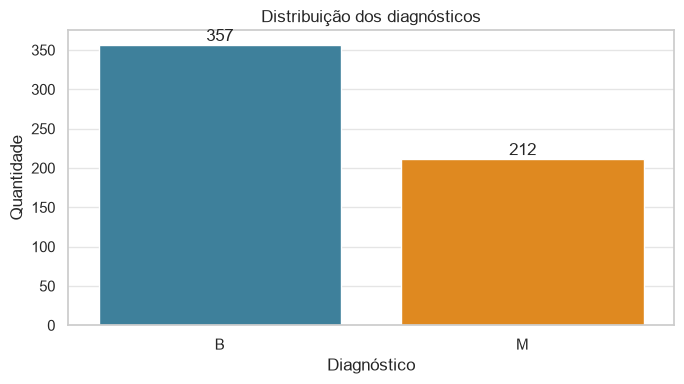

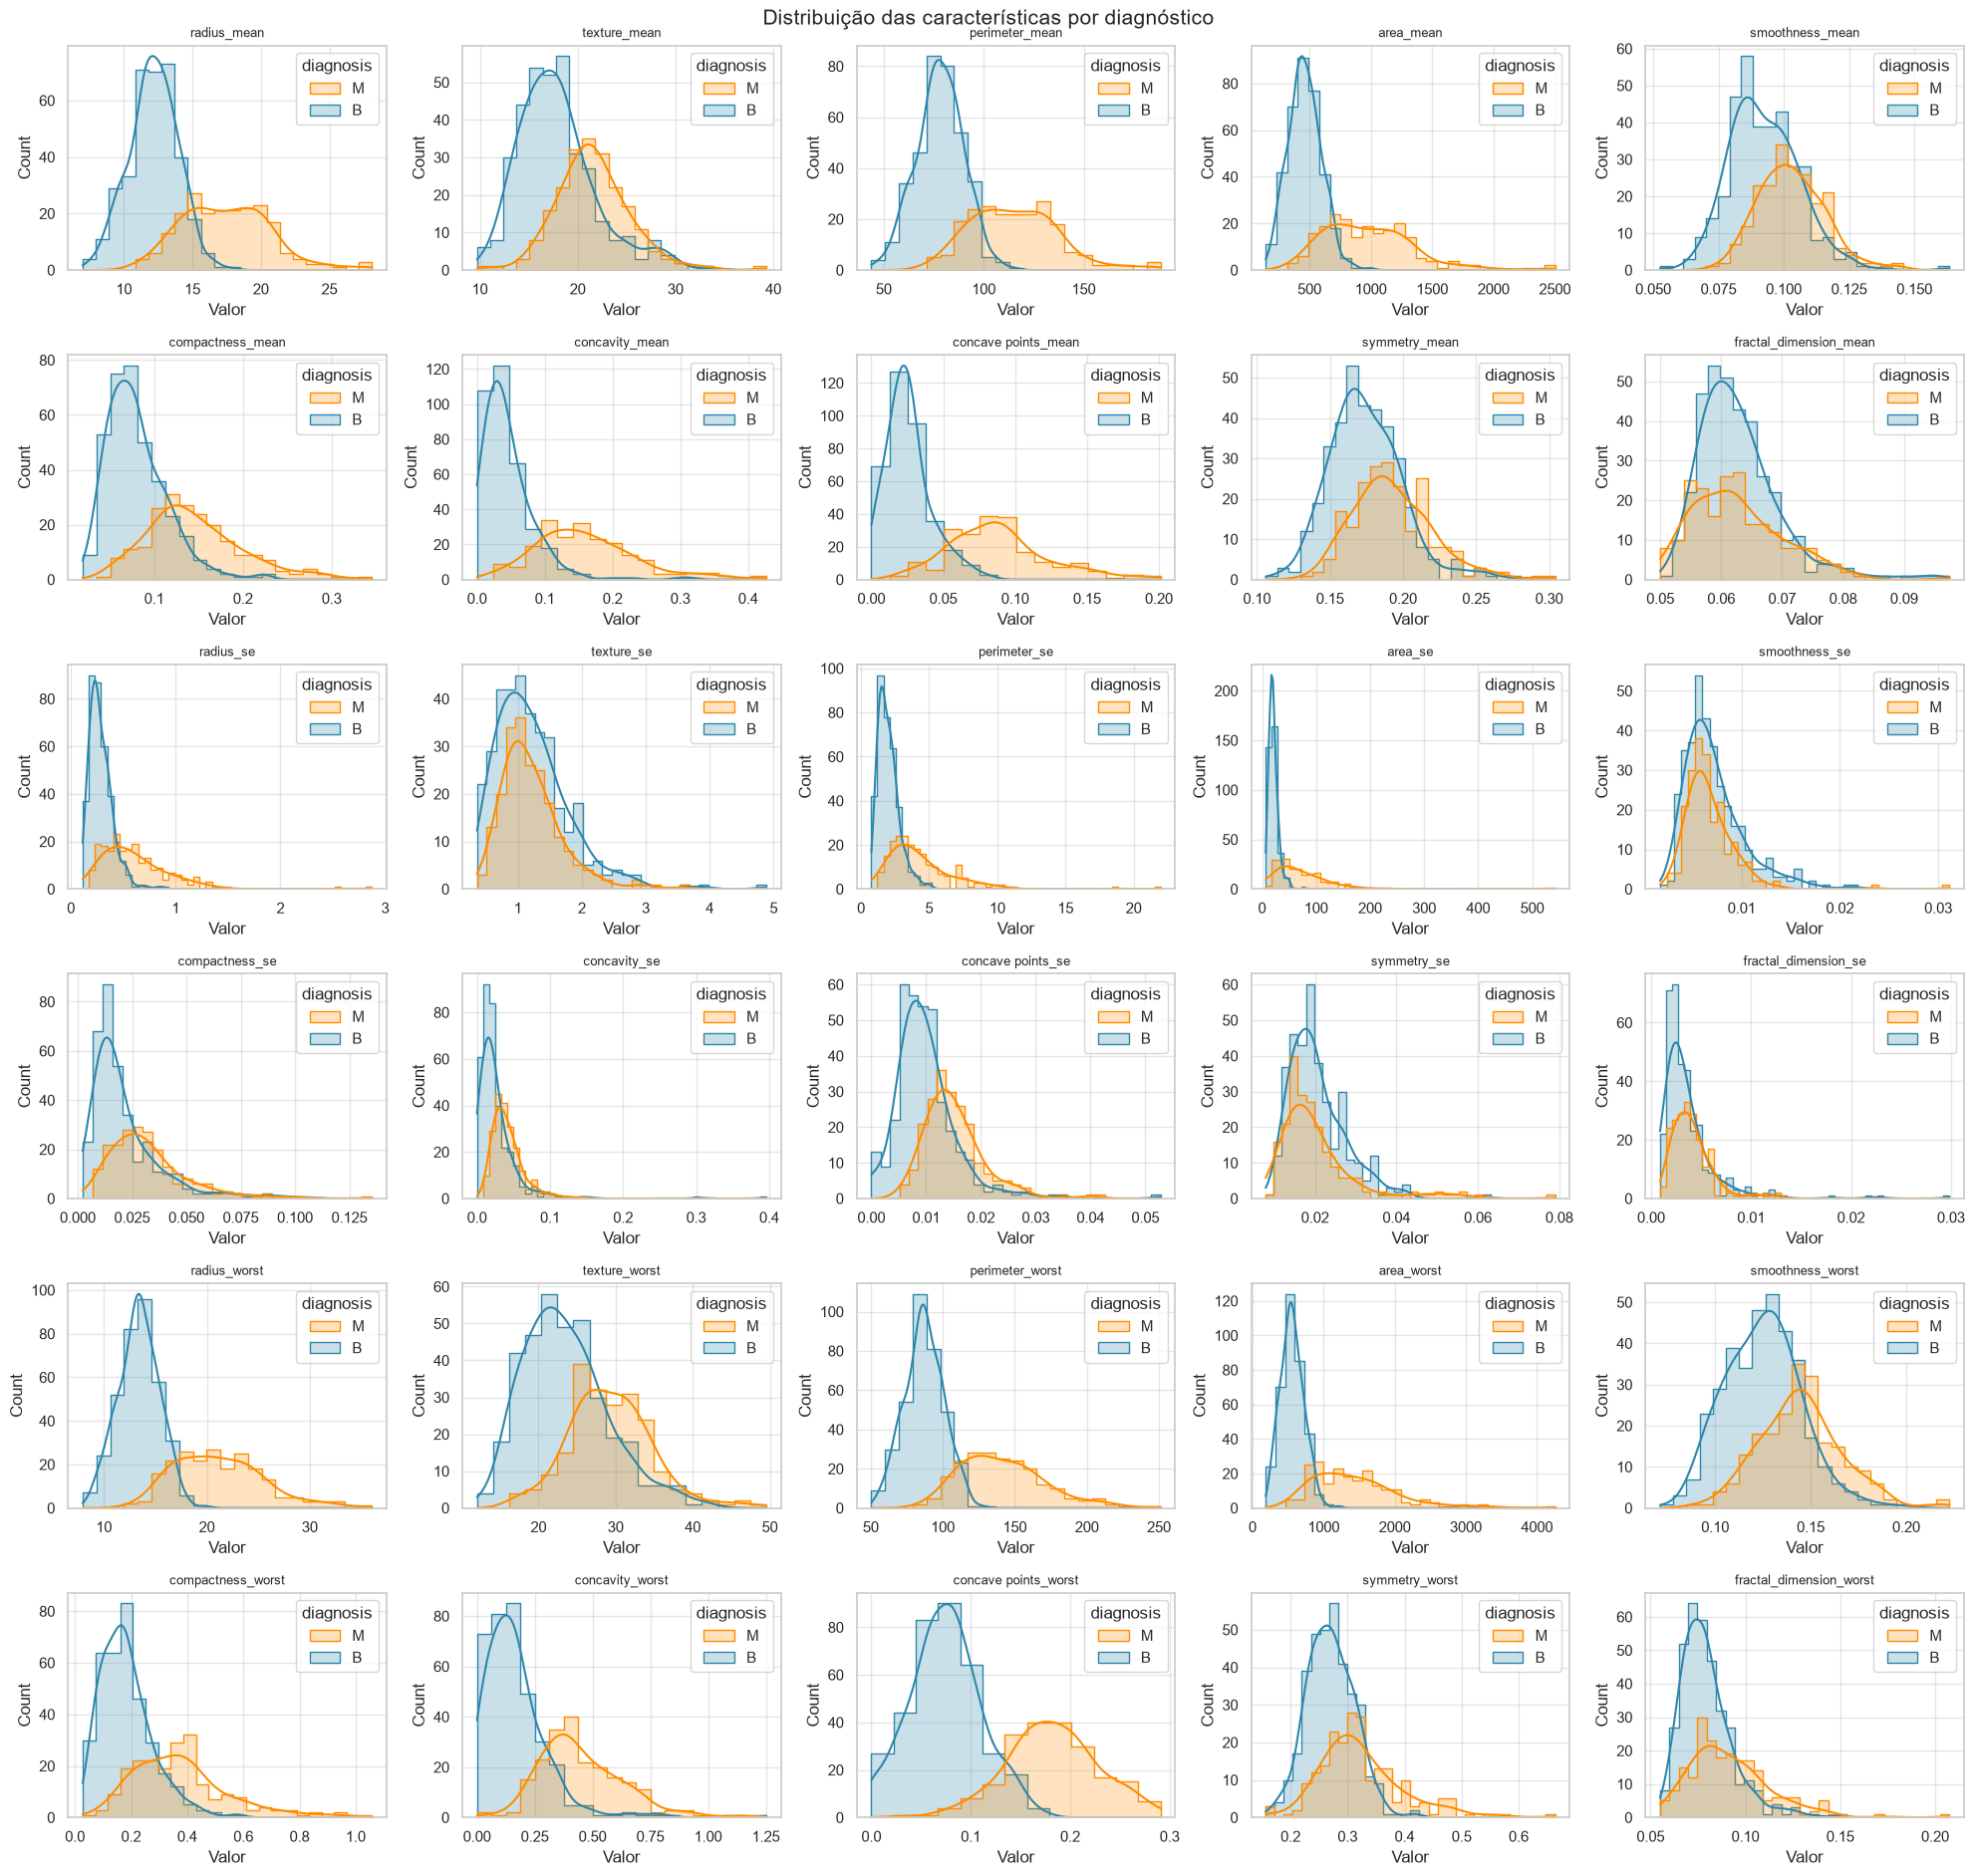

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df_original, x=TARGET, hue=TARGET, order=["B", "M"],
              palette={"B": "#2E86AB", "M": "#FF8C00"}, legend=False, ax=ax)
ax.set(title="Distribuição dos diagnósticos", xlabel="Diagnóstico", ylabel="Quantidade")
for container in ax.containers:
    ax.bar_label(container)
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / "distribuicao_diagnosticos.png", dpi=200, bbox_inches="tight")
plt.show()

feature_columns_original = [c for c in df_original.columns if c not in (TARGET, ID_COLUMN)]
numeric_features_original = [c for c in df_original[feature_columns_original].select_dtypes(include=np.number).columns if df_original[c].notna().any()]
ncols = 5
nrows = max(1, int(np.ceil(len(numeric_features_original) / ncols)))
fig, axes = plt.subplots(nrows, ncols, figsize=(20, max(4, nrows * 3.2)))
axes = np.asarray(axes).reshape(-1)
for ax, column in zip(axes, numeric_features_original):
    sns.histplot(data=df_original, x=column, hue=TARGET,
                 palette={"B": "#2E86AB", "M": "#FF8C00"},
                 element="step", kde=True, ax=ax)
    ax.set_title(column, fontsize=9)
    ax.set_xlabel("Valor")
for ax in axes[len(numeric_features_original):]:
    fig.delaxes(ax)
fig.suptitle("Distribuição das características por diagnóstico", fontsize=15)
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / "distribuicao_caracteristicas.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Limpeza, transformação e correlações

Colunas totalmente vazias e identificadores são removidos. Linhas sem diagnóstico não podem participar do treinamento. Os demais valores ausentes são imputados dentro dos pipelines, ajustados somente com os dados de treino para evitar vazamento de informação.

Dados preparados: 569 registros e 30 características.
Mapeamento do alvo: benigno = 0; maligno = 1.


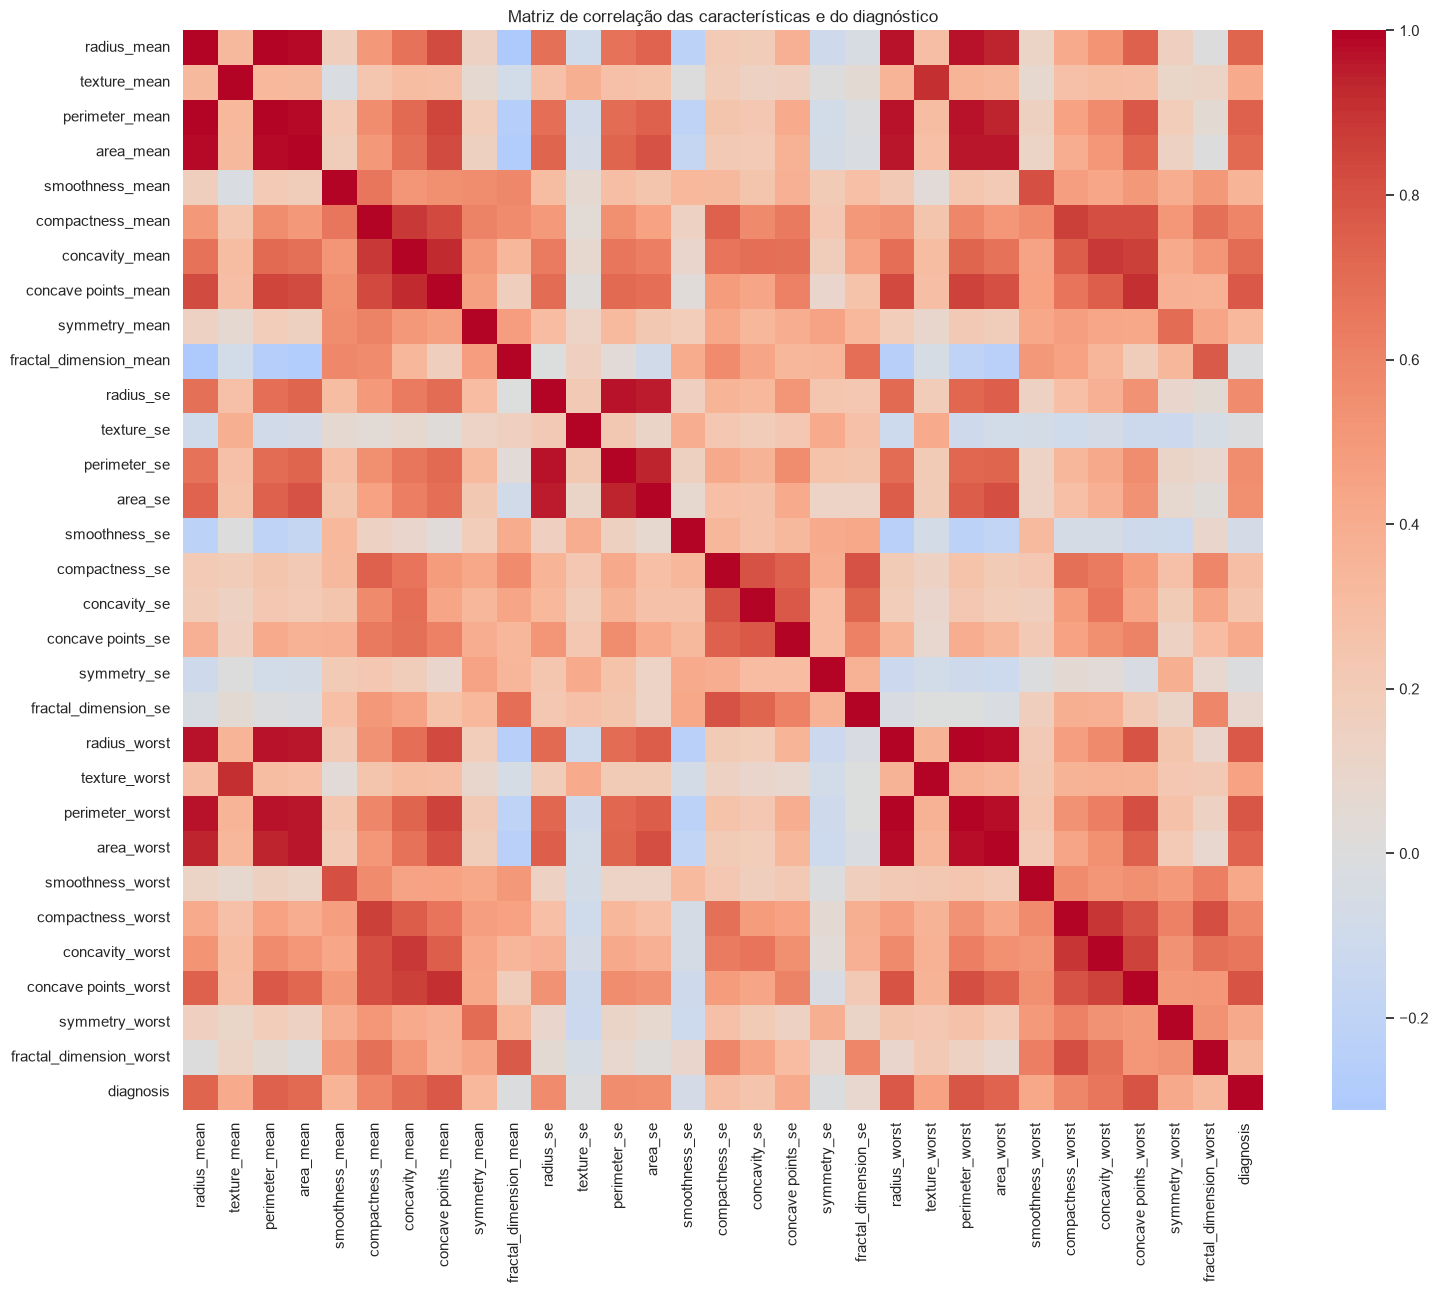

,correlacao_com_diagnostico
concave points_worst,0.793566
perimeter_worst,0.782914
concave points_mean,0.776614
radius_worst,0.776454
perimeter_mean,0.742636
area_worst,0.733825
radius_mean,0.730029
area_mean,0.708984
concavity_mean,0.696360
concavity_worst,0.659610


In [6]:
df = df_original.dropna(axis=1, how="all").copy()
df = df.dropna(subset=[TARGET]).copy()
df[TARGET] = df[TARGET].replace({"B": 0, "M": 1, "b": 0, "m": 1})
df[TARGET] = pd.to_numeric(df[TARGET], errors="raise").astype(int)
if not set(df[TARGET].unique()).issubset({0, 1}):
    raise ValueError("A coluna diagnosis deve conter somente B/M ou 0/1.")
X = df.drop(columns=[TARGET, ID_COLUMN], errors="ignore").copy()
y = df[TARGET].copy()
X = X.apply(pd.to_numeric, errors="raise")
if X.shape[1] == 0:
    raise ValueError("Nenhuma característica numérica foi encontrada para treinar os modelos.")
print(f"Dados preparados: {X.shape[0]} registros e {X.shape[1]} características.")
print("Mapeamento do alvo: benigno = 0; maligno = 1.")

correlation_data = X.assign(diagnosis=y)
correlation = correlation_data.corr(numeric_only=True)
correlation.to_csv(GRAPHICS_DIR / "matriz_correlacao.csv")
fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(correlation, cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Matriz de correlação das características e do diagnóstico")
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / "matriz_correlacao.png", dpi=200, bbox_inches="tight")
plt.show()
display(correlation["diagnosis"].drop("diagnosis").sort_values(key=abs, ascending=False).head(10).to_frame("correlacao_com_diagnostico"))

## 4. Separação treino, validação e teste

A separação estratificada preserva a proporção entre as classes: 60% para treino, 20% para validação e 20% para teste. O conjunto de teste fica reservado até a escolha do modelo.

In [7]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)
print(f"Treino: {len(X_train)} ({len(X_train) / len(X):.0%})")
print(f"Validação: {len(X_val)} ({len(X_val) / len(X):.0%})")
print(f"Teste: {len(X_test)} ({len(X_test) / len(X):.0%})")

Treino: 341 (60%)
Validação: 114 (20%)
Teste: 114 (20%)


## 5. Modelagem e seleção na validação

Comparamos regressão logística (com padronização) e floresta aleatória. A imputação e a padronização são aprendidas apenas no treino. O modelo é escolhido pela maior sensibilidade (recall) para malignidade e, em caso de empate, pelo F1-score.

In [8]:
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE)),
])
forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(n_estimators=400, class_weight="balanced",
                                          random_state=RANDOM_STATE, n_jobs=-1)),
])
models = {"Regressão logística": logistic_model, "Floresta aleatória": forest_model}
validation_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]
    validation_rows.append({
        "modelo": name,
        "acurácia": accuracy_score(y_val, predictions),
        "precisão (maligno)": precision_score(y_val, predictions, zero_division=0),
        "recall (maligno)": recall_score(y_val, predictions, zero_division=0),
        "F1 (maligno)": f1_score(y_val, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
    })
validation_results = pd.DataFrame(validation_rows).set_index("modelo")
display(validation_results.sort_values(["recall (maligno)", "F1 (maligno)"], ascending=False))
best_model_name = validation_results.sort_values(
    ["recall (maligno)", "F1 (maligno)"], ascending=False
).index[0]
best_model = models[best_model_name]
print(f"Modelo selecionado na validação: {best_model_name}")

,acurácia,precisão (maligno),recall (maligno),F1 (maligno),ROC-AUC
modelo,,,,,
Regressão logística,0.982456,1.00000,0.953488,0.976190,1.000000
Floresta aleatória,0.964912,0.97561,0.930233,0.952381,0.996397


Modelo selecionado na validação: Regressão logística


## 6. Avaliação final no conjunto de teste

As métricas abaixo são calculadas uma única vez no conjunto reservado. Recall mede a proporção de casos malignos identificados; precisão indica quantos dos casos previstos como malignos realmente são malignos. Nenhuma métrica isolada torna o modelo apropriado para uso clínico.

,resultado no teste
acurácia,0.956140
precisão (maligno),0.974359
recall (maligno),0.904762
F1 (maligno),0.938272
ROC-AUC,0.992725


              precision    recall  f1-score   support

     Benigno       0.95      0.99      0.97        72
     Maligno       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



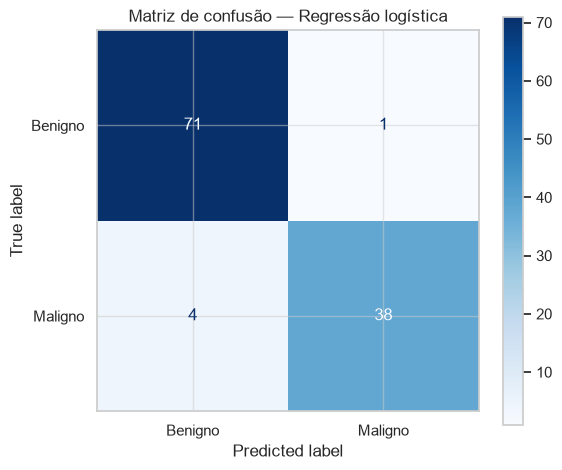

In [9]:
test_predictions = best_model.predict(X_test)
test_probabilities = best_model.predict_proba(X_test)[:, 1]
test_metrics = pd.Series({
    "acurácia": accuracy_score(y_test, test_predictions),
    "precisão (maligno)": precision_score(y_test, test_predictions, zero_division=0),
    "recall (maligno)": recall_score(y_test, test_predictions, zero_division=0),
    "F1 (maligno)": f1_score(y_test, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
}, name=best_model_name)
display(test_metrics.to_frame("resultado no teste"))
print(classification_report(y_test, test_predictions, target_names=["Benigno", "Maligno"], zero_division=0))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, test_predictions,
    display_labels=["Benigno", "Maligno"], cmap="Blues", values_format="d", ax=ax)
ax.set_title(f"Matriz de confusão — {best_model_name}")
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / "matriz_confusao_teste.png", dpi=200, bbox_inches="tight")
plt.show()
test_metrics.to_frame("valor").to_csv(RESULTS_DIR / "metricas_teste.csv")

## 7. Interpretação das características

Para a floresta, usamos importância por impureza; para a regressão logística, mostramos o valor absoluto dos coeficientes padronizados. Essas medidas ajudam a interpretar o modelo, mas não demonstram causalidade.

,|Coeficiente padronizado|
radius_se,1.225657
texture_worst,1.205143
symmetry_worst,1.097883
concave points_mean,0.994487
perimeter_se,0.945896
area_se,0.933350
concave points_worst,0.883110
concavity_mean,0.813710
compactness_se,0.806057
area_worst,0.759819


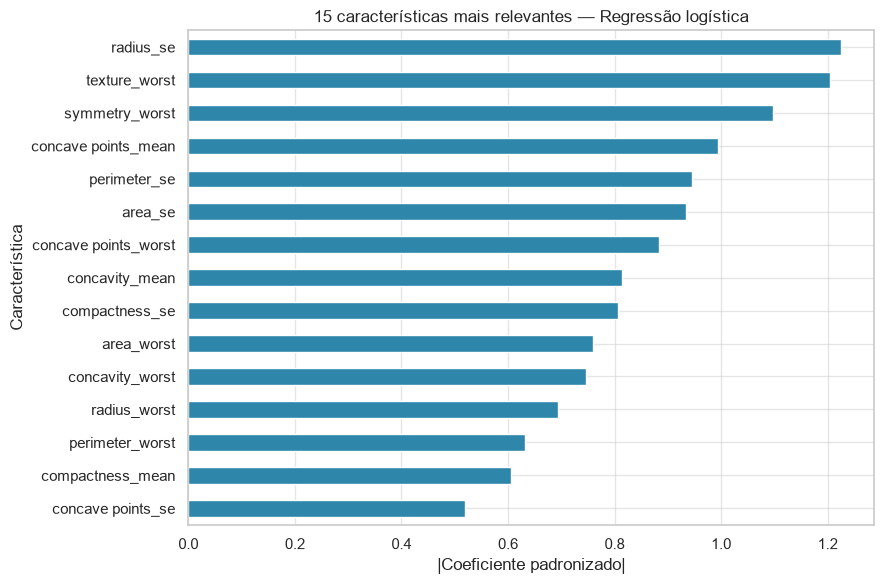

In [10]:
classifier = best_model.named_steps["classifier"]
if hasattr(classifier, "feature_importances_"):
    importance_values = classifier.feature_importances_
    importance_label = "Importância"
else:
    importance_values = np.abs(classifier.coef_[0])
    importance_label = "|Coeficiente padronizado|"
importance = pd.Series(importance_values, index=X.columns, name=importance_label).sort_values(ascending=False)
display(importance.head(15).to_frame())
fig, ax = plt.subplots(figsize=(9, 6))
importance.head(15).sort_values().plot.barh(ax=ax, color="#2E86AB")
ax.set(title=f"15 características mais relevantes — {best_model_name}", xlabel=importance_label, ylabel="Característica")
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / "importancia_caracteristicas.png", dpi=200, bbox_inches="tight")
plt.show()
importance.to_frame().to_csv(RESULTS_DIR / "importancia_caracteristicas.csv")

## 8. Exportação dos resultados

Os gráficos e tabelas são reunidos em `../resultados_cancer_de_mama.zip`. No Colab, a última linha inicia o download do arquivo.

In [11]:
zip_path = Path("../resultados_cancer_de_mama.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for file_path in RESULTS_DIR.rglob("*"):
        if file_path.is_file():
            archive.write(file_path, arcname=file_path.as_posix())
print(f"Resultados salvos em: {zip_path.resolve()}")
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print("No Colab, o arquivo será baixado automaticamente. Localmente, use o ZIP acima.")

Resultados salvos em: C:\Users\hb06a\PycharmProjects\TC1_Projeto_feito_na_mao\tc1_cancer_de_mama\resultados_cancer_de_mama.zip
No Colab, o arquivo será baixado automaticamente. Localmente, use o ZIP acima.


## Conclusão

A seleção foi realizada na validação e o teste foi mantido separado para estimar o desempenho final. Antes de qualquer aplicação real seriam necessários validação externa, revisão clínica, análise de vieses, calibração e definição de um limiar de decisão com especialistas. Este modelo deve ser tratado somente como demonstração acadêmica.